Predicting Stock Market Prices	Conduct an in-depth correlation analysis to quantify and interpret the relationships between the engineered technical indicators and TSLA stock prices, identifying highly influential predictors for model development.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load and sort dataset chronologically
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# 1. Returns & Next-Day Target (to evaluate true forecasting power)
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))
df['Next_Close'] = df['Close'].shift(-1)

# 2. Moving Averages (SMA & EMA)
df['SMA_7'] = df['Close'].rolling(window=7).mean()
df['SMA_10'] = df['Close'].rolling(window=10).mean()
df['SMA_20'] = df['Close'].rolling(window=20).mean()
df['EMA_7'] = df['Close'].ewm(span=7, adjust=False).mean()
df['EMA_12'] = df['Close'].ewm(span=12, adjust=False).mean()
df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()
df['EMA_26'] = df['Close'].ewm(span=26, adjust=False).mean()

# 3. Lagged Close Features
for lag in [1, 2, 3, 5, 7, 14]:
    df[f'Close_Lag_{lag}'] = df['Close'].shift(lag)

# 4. Relative Strength Index (RSI-14)
delta = df['Close'].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
df['RSI_14'] = 100 - (100 / (1 + (avg_gain / avg_loss)))

# 5. MACD (12, 26, 9)
df['MACD'] = df['EMA_12'] - df['EMA_26']
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

# 6. Bollinger Bands (20-day, 2 std)
df['BB_Upper'] = df['SMA_20'] + (2 * df['Close'].rolling(window=20).std())
df['BB_Lower'] = df['SMA_20'] - (2 * df['Close'].rolling(window=20).std())
df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['SMA_20']
df['BB_PctB'] = (df['Close'] - df['BB_Lower']) / (df['BB_Upper'] - df['BB_Lower'])

# Clean warm-up NaNs
df_clean = df.dropna().reset_index(drop=True)
print(f"Clean modeling dataset: {df_clean.shape[0]} rows x {df_clean.shape[1]} columns")

Clean modeling dataset: 80 rows x 29 columns


In [4]:
exclude_cols = ['Date', 'Open', 'High', 'Low', 'Close', 'Next_Close']
feature_cols = [col for col in df_clean.columns if col not in exclude_cols]

# Compute linear (Pearson) and monotonic (Spearman) correlations
corr_summary = pd.DataFrame({
    'Pearson_Close': df_clean[feature_cols].corrwith(df_clean['Close'], method='pearson'),
    'Spearman_Close': df_clean[feature_cols].corrwith(df_clean['Close'], method='spearman'),
    'Pearson_Next_Close': df_clean[feature_cols].corrwith(df_clean['Next_Close'], method='pearson')
})

# Rank predictors by absolute Pearson correlation with Close
corr_summary['Abs_Pearson'] = corr_summary['Pearson_Close'].abs()
corr_summary = corr_summary.sort_values('Abs_Pearson', ascending=False).drop(columns=['Abs_Pearson'])

print("--- Ranked Predictor Correlations with TSLA Close & Next-Day Close ---")
print(corr_summary.round(4).to_string())

# Identify high-impact predictors (|r| >= 0.70) vs. non-redundant oscillators
strong_predictors = corr_summary[corr_summary['Pearson_Close'].abs() >= 0.70].index.tolist()
print(f"\nStrong Linear Predictors (|r| >= 0.70): {strong_predictors}")

--- Ranked Predictor Correlations with TSLA Close & Next-Day Close ---
              Pearson_Close  Spearman_Close  Pearson_Next_Close
Close_Lag_1          0.9448          0.9213              0.8785
EMA_7                0.9407          0.9036              0.8869
SMA_7                0.9073          0.8426              0.8546
EMA_12               0.9025          0.8393              0.8552
Close_Lag_2          0.8879          0.8324              0.8232
SMA_10               0.8789          0.7858              0.8390
BB_Upper             0.8705          0.7727              0.8312
EMA_20               0.8485          0.7424              0.8033
Close_Lag_3          0.8383          0.7487              0.7953
SMA_20               0.8366          0.7234              0.8011
EMA_26               0.8121          0.6727              0.7664
Close_Lag_5          0.7833          0.6653              0.7401
BB_Lower             0.7663          0.6799              0.7360
Close_Lag_14         0.7410      

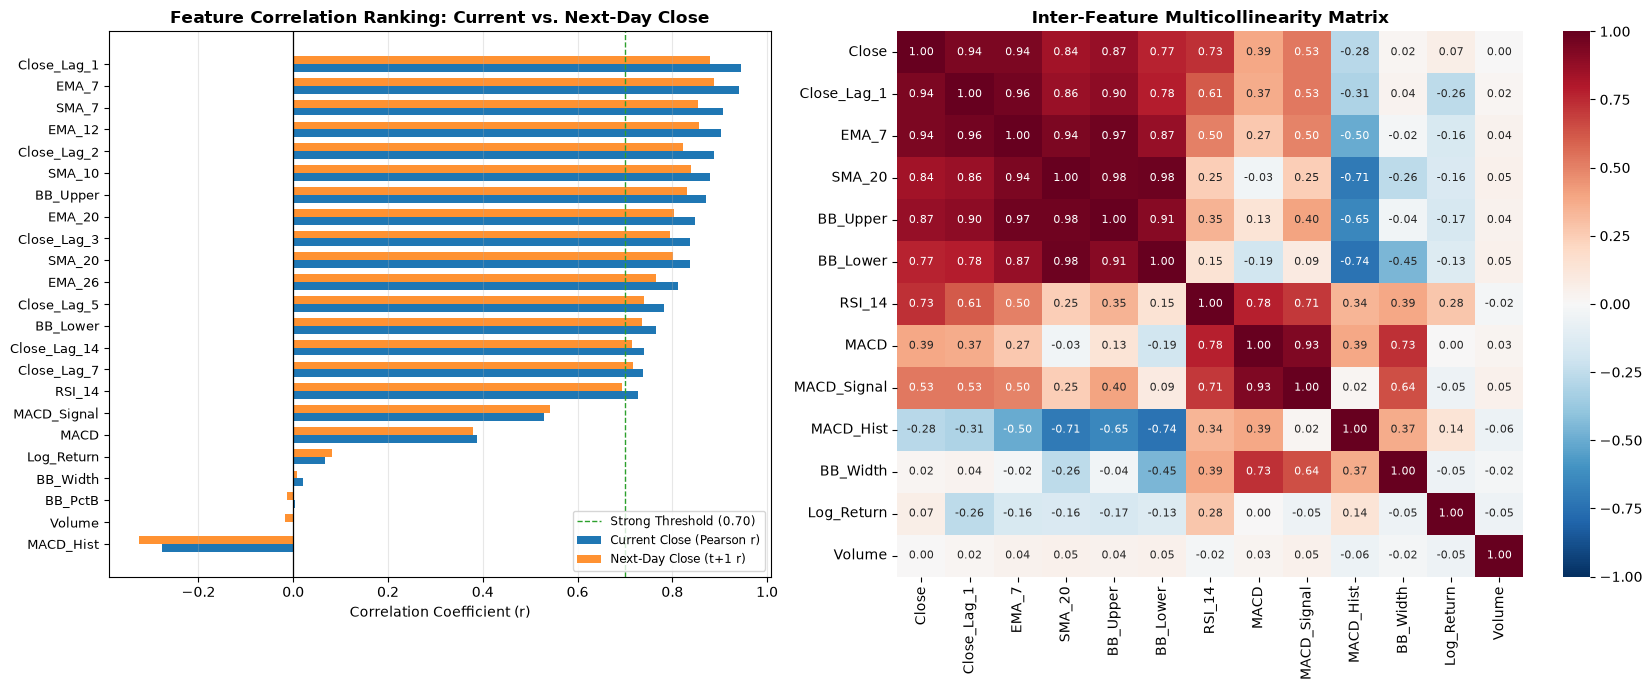

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1.1, 1.3]})

# Plot 1: Horizontal Bar Chart of Pearson vs. Next-Day Predictive Correlation
plot_df = corr_summary.sort_values('Pearson_Close', ascending=True)
y_pos = np.arange(len(plot_df))

axes[0].barh(y_pos - 0.18, plot_df['Pearson_Close'], height=0.36, color='#1f77b4', label='Current Close (Pearson r)')
axes[0].barh(y_pos + 0.18, plot_df['Pearson_Next_Close'], height=0.36, color='#ff7f0e', alpha=0.85, label='Next-Day Close (t+1 r)')
axes[0].axvline(0, color='black', linewidth=0.9)
axes[0].axvline(0.7, color='#2ca02c', linestyle='--', linewidth=1, label='Strong Threshold (0.70)')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_df.index, fontsize=9)
axes[0].set_xlabel('Correlation Coefficient (r)')
axes[0].set_title('Feature Correlation Ranking: Current vs. Next-Day Close', fontsize=12, fontweight='bold')
axes[0].legend(loc='lower right', fontsize=8.5)
axes[0].grid(axis='x', alpha=0.3)

# Plot 2: Inter-Feature Multicollinearity Heatmap (Candidate Model Subset)
candidate_features = [
    'Close', 'Close_Lag_1', 'EMA_7', 'SMA_20', 'BB_Upper', 'BB_Lower',
    'RSI_14', 'MACD', 'MACD_Signal', 'MACD_Hist', 'BB_Width', 'Log_Return', 'Volume'
]
corr_matrix = df_clean[candidate_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot_kws={'size': 8}, ax=axes[1])
axes[1].set_title('Inter-Feature Multicollinearity Matrix', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()